# Hälsostudie – Del 2

## 1. Kodstruktur och beskrivande statistik

I denna del har analyskoden från Del 1 organiserats i funktioner, moduler och en klass. Funktionen `calculate_statistics()` finns i `src/analysis.py` och beräknar medelvärde, median, minimum och maximum för de utvalda hälsovariablerna.

Klassen `HealthAnalyzer` finns i `src/health_analyzer.py` och samlar metoder för beskrivande statistik, linjär regression och visualiseringar. Genom att flytta beräkningarna från notebooken till separata Python-filer blir koden enklare att återanvända och underhålla.

Den beskrivande statistiken ger samma resultat som i Del 1, vilket visar att omstruktureringen inte har förändrat beräkningarna.

In [1]:

import sys
from pathlib import Path
import pandas as pd

# Hitta egna Python-filer
sys.path.insert(0, str(Path.cwd().parent / "src"))

from health_analyzer import HealthAnalyzer

# Läs in data
df = pd.read_csv("../data/health_study_dataset.csv")

# Skapa objekt och visa statistik
health = HealthAnalyzer(df)
health.get_stats()

,mean,median,min,max
age,49.43,50.00,18.0,90.00
weight,73.41,73.20,33.7,114.40
height,171.85,171.35,144.4,200.40
systolic_bp,149.18,149.40,106.8,185.90
cholesterol,4.93,4.97,2.5,7.88


## 2. Linjär regression och sambandet mellan ålder och blodtryck

För att undersöka sambandet mellan ålder och systoliskt blodtryck används enkel linjär regression med NumPy.

Ålder är den **oberoende variabeln (X)** och systoliskt blodtryck är den **beroende variabeln (Y)**. Med hjälp av minsta kvadratmetoden beräknas en regressionslinje som beskriver det linjära sambandet mellan variablerna.

Regressionslinjens **lutningskoefficient** visar hur mycket det förväntade blodtrycket förändras när åldern ökar med ett år. **Interceptet** anger linjens förväntade blodtryck vid åldern noll år.

Lutningskoefficient: 0.54
Intercept: 122.68
R²: 0.369


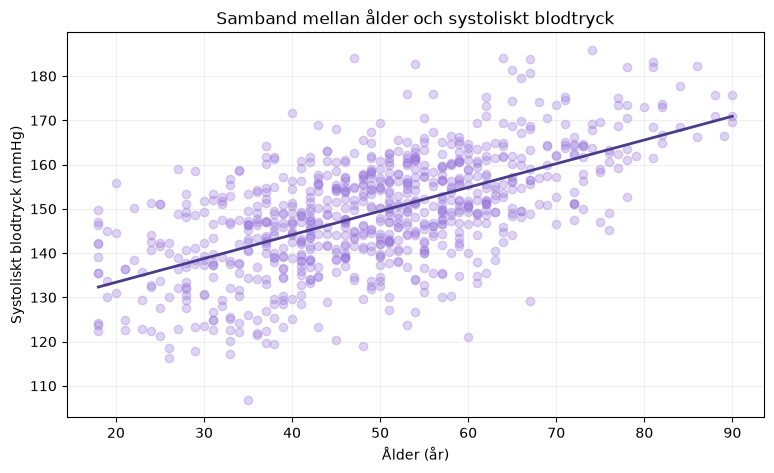

In [2]:

health.get_regression_results()
health.plot_regression()

### Resultat och tolkning

Den linjära regressionen visar ett positivt samband mellan ålder och systoliskt blodtryck.

**Lutningskoefficienten är 0,54**, vilket innebär att det förväntade systoliska blodtrycket ökar med ungefär 0,54 mmHg för varje år som åldern ökar, enligt modellen.

**Interceptet är 122,68 mmHg** och anger det förväntade blodtrycket vid 0 års ålder. Eftersom undersökningen gäller vuxna är interceptet främst ett matematiskt värde och har ingen praktisk betydelse i det här sammanhanget.

**Förklaringsgraden (R²) är 0,369**, vilket innebär att modellen förklarar ungefär 36,9 % av variationen i systoliskt blodtryck. Resterande variation förklaras inte av modellen och kan bero på andra faktorer.

Resultatet tyder på att ålder har ett samband med systoliskt blodtryck i datasetet, men att ålder ensam inte räcker för att förklara alla skillnader. Regressionen visar ett statistiskt samband, inte att ålder i sig har bevisats orsaka förändringen.

## 3. Residualanalys

För att undersöka hur väl den linjära regressionsmodellen passar våra data görs en residualanalys.

En **residual** är skillnaden mellan ett observerat värde och det värde som modellen förutsäger:

$
e_i = y_i - \hat{y}_i
$

I residualdiagrammet visas residualerna i förhållande till de förutsagda blodtrycksvärdena.

Om residualerna är slumpmässigt fördelade runt noll utan något tydligt mönster talar det för att en linjär modell är rimlig. Tydliga mönster kan däremot tyda på att modellen inte fångar sambandet tillräckligt väl.

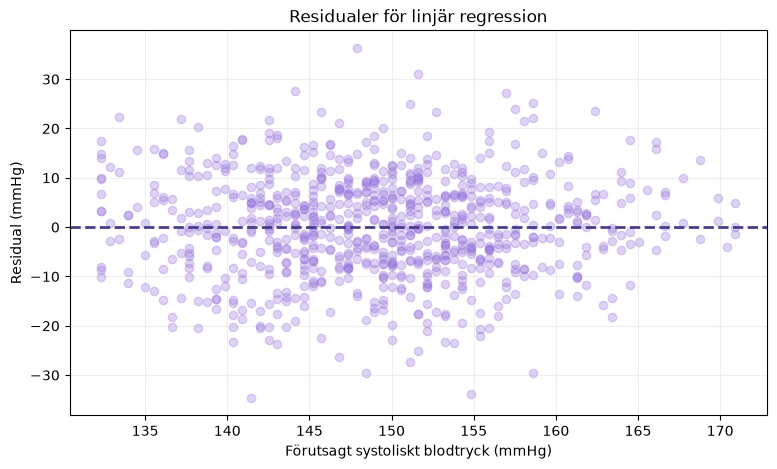

In [3]:
health.plot_residuals()

### Resultat och tolkning

Residualdiagrammet visar att residualerna är spridda på båda sidor om nollinjen utan något tydligt systematiskt mönster. Spridningen verkar också vara relativt jämn över de förutsagda blodtrycksvärdena.

Detta tyder på att en linjär regressionsmodell är rimlig för datasetet. Samtidigt finns det relativt stora avvikelser mellan observerade och förutsagda värden.

Tillsammans med förklaringsgraden på 36,9 % visar residualanalysen att ålder har ett tydligt samband med systoliskt blodtryck, men att modellen inte fångar all variation i blodtrycket.